- ***HITL(Human In The Loop)***
   - ***HITL is a design approach where a human checkpoint is placed inside an AI pipeline to supervise, approve, correct, or guide the model’s actions before final execution.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import AIMessage,HumanMessage,BaseMessage
from langgraph.graph import StateGraph,START,END 
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt,Command
from typing import TypedDict,Annotated

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# Define Our Model
LLM = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.7
)

In [3]:
# Define State 
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# Add HITL Node
def chat_node(state: ChatState):
    decision = interrupt({
        "type": "approval",
        "reason": "Model is about to answer a user question.",
        "question": state["messages"][-1].content,
        "instruction": "Approve this question? yes/no"
    })
    
    if decision["approved"] == 'no':
        return {"messages": [AIMessage(content="Not approved.")]}

    else:
        response = llm.invoke(state["messages"])
        return {"messages": [response]}

In [4]:
#  Build the graph: START -> chat -> END
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

# Checkpointer is required for interrupts
checkpointer = MemorySaver()

# Compile the app
app = builder.compile(checkpointer=checkpointer)

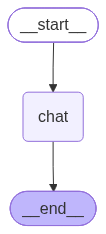

In [5]:
from IPython.display import Image 
Image(app.get_graph().draw_mermaid_png())

In [6]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

result = app.invoke(
    {
        "messages": [HumanMessage(content="Explain gradient descent")]
    },
    config=config
)

In [7]:
result

{'messages': [HumanMessage(content='Explain gradient descent', additional_kwargs={}, response_metadata={}, id='44d9c11f-25ef-470f-8f91-9f91c2e96712')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'Explain gradient descent', 'instruction': 'Approve this question? yes/no'}, id='2e1aee5a80d6e639da488faabaa9c971')]}

In [8]:
message = result['__interrupt__'][0].value
message

{'type': 'approval',
 'reason': 'Model is about to answer a user question.',
 'question': 'Explain gradient descent',
 'instruction': 'Approve this question? yes/no'}

In [9]:
user_input = input(f"\nBackend message - {message} \n Approve this question? (y/n): ")

In [10]:
# Resume the graph with the approval decision
final_result = app.invoke(
    Command(resume={"approved": user_input}),
    config=config,
)

In [11]:
print(final_result["messages"][-1].content)

Imagine you're lost in the mountains, blindfolded, and your goal is to reach the lowest point (the valley). You can't see the entire landscape, but you can feel the slope directly beneath your feet.

**Gradient Descent** is an optimization algorithm that works much like this scenario. It's a fundamental technique used in machine learning to find the best set of parameters (like weights and biases in a neural network, or coefficients in a linear regression model) that minimize a "cost function" (or "loss function").

---

### The Core Idea: Iteratively Moving Downhill

At its heart, Gradient Descent is an iterative optimization algorithm. It starts with an initial set of parameters and repeatedly adjusts them in the direction that most steeply decreases the cost function.

Let's break down the key components:

1.  **Cost Function (or Loss Function - $J(\theta)$):**
    *   **What it is:** This function measures how "wrong" our model is. A higher cost means the model is performing poorly

- ***Code Exmaple To Understand HITL***

In [12]:
from langgraph.graph import StateGraph,START,END 
from typing import TypedDict

# Define State 
class State(TypedDict):
    email:str
    approved:bool

In [15]:
# Define Node 
def generate_email(state):
    return{
        "email":"Hello User I am Email Genrator..!"
    }

def approval(state):
    ans = input("Approved..? (yes/no)")
    return{
        "approved":ans=="yes"
    }

def send_email(state):
    if state["approved"]:
        print("email sent success..✅")
    else:
        print("rejected..❌")
    return {}

In [16]:
builder=StateGraph(State)

builder.add_node("generate",generate_email)
builder.add_node("approve",approval)
builder.add_node("send",send_email)

builder.add_edge(START,"generate")
builder.add_edge("generate","approve")
builder.add_edge("approve","send")
builder.add_edge("send",END)

graph=builder.compile()

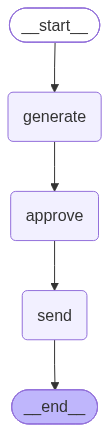

In [17]:
graph

In [18]:
graph.invoke({})

email sent success..✅


{'email': 'Hello User I am Email Genrator..!', 'approved': True}